# Traballo 

En base ás outras columnas predecir os valores crash_risk_level. Análise de regresión con sklearn e rede neuronal con tensorflow, empregamos seaborn para representación de datos

O traballo pretende predecir puntuacións de crash_risk_level for caffeine mediante un dataframe de condicións biolóxicas e sociais como de habitos de conduta. Non entendamos isto como un diagnóstico senón como un por centaxe de factor de risco.

Teños dúas opcións: ou determino a variable str <<crash_risk_level>> ou determio numéricamente <<crash_severity_score>>. Creo que facer a primeira é o correcto, a segunda é unha variable continua e debería separala en rangos o que daría moi erro nas fronteiras.

## 1. Depuración de datos

## Pendente!!!
Teño que depurar o código en xeral e ordear os códigos de sklearn, logo divir un caso no que non elimino os scores e só uso linear e rbf (dan moi ben) calculando o alpha óptimo de linear a man. Logo repito eliminando esa columna e engado árboles e emprego GridSearchCV para optimizar os parámetros. Se podo talvez sería interesante utilizar os modelo de SVR (regresións) para predecir os scores quitando tamén a columna de risk. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import sys
import os
# sys.path.append(os.path.dirname(os.path.abspath(____)))
sys.path.append(os.getcwd()) # solución de ia, non entendo a diferenza

In [2]:
df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv') # https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset/data
df.head()

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


In [3]:
df.info() # sinala automaticamente onde hai valores nulos e o tipo de columna

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   str    
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   str    
 3   cyp1a2_metabolizer_type   8000 non-null   str    
 4   caffeine_tolerance        8000 non-null   str    
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   str    
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   float64
 14  acute_anxiety_score

In [4]:
# agora vemos datos máis pormenorizadamente, e.g., para <<crash_risk_level>> porque pretenderemos predicila, podemos ver calquera dascolumnas que nos devolve df.info()
print(f"{'crash_risk_level'}: {df['crash_risk_level'].describe()}")
df.crash_risk_level.unique()

crash_risk_level: count                          8000
unique                            4
top       Moderate Crash & Lethargy
freq                           2426
Name: crash_risk_level, dtype: object


<StringArray>
[      'Mild Afternoon Fatigue', 'Sustained / Negligible Crash',
    'Moderate Crash & Lethargy',   'Severe Crash & Tachycardia']
Length: 4, dtype: str

Vemos que temos dúas columnas (Medication_Use e Substance_Use) que teñen celas baleiras e as columnas 'Gender', 'Education_Level', 'Employment_Status' e as xa mencionadas son strings. Esos datos teremos que depuralos

In [5]:
for i in range(1,len(df.columns)):
    if df[df.columns[i]].dtypes == 'str':
        print(f'Na columna <<{df.columns[i]}>> pódense tomar os seguintes valores {df[df.columns[i]].unique()}')

s = 0 # isto serve para contar cantos suxeitos satisfan certo valor
for i in range(len(df)):
    if df['gender'].iloc[i] == 'Non-Binary':
        s += 1
print(s)

Na columna <<gender>> pódense tomar os seguintes valores <StringArray>
['Female', 'Male', 'Non-Binary']
Length: 3, dtype: str
Na columna <<cyp1a2_metabolizer_type>> pódense tomar os seguintes valores <StringArray>
['Fast', 'Normal', 'Slow']
Length: 3, dtype: str
Na columna <<caffeine_tolerance>> pódense tomar os seguintes valores <StringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str
Na columna <<primary_caffeine_source>> pódense tomar os seguintes valores <StringArray>
[         'Brewed Drip Coffee',   'Energy Drink (Sugar-Free)',
   'Energy Drink (Full Sugar)',      'Pre-Workout Supplement',
 'Espresso / Specialty Drinks',          'Matcha / Green Tea']
Length: 6, dtype: str
Na columna <<crash_risk_level>> pódense tomar os seguintes valores <StringArray>
[      'Mild Afternoon Fatigue', 'Sustained / Negligible Crash',
    'Moderate Crash & Lethargy',   'Severe Crash & Tachycardia']
Length: 4, dtype: str
231


Segundo os valores que vemos, as variables <<cyp1a2_metabolizer_type>> e <<caffeine_tolerance>> pódense poñer perfectamente como datos numéricos cun diccionario. Para os casos <<gender>>, <<primary_caffeine_source>> e <<crash_risk_level>> o mellor é traballar con variables dummies. ¿<<crash_risk_level>> non fará falla realmente? Decatémonos que a primeira columna non nos aporta ningunha información, é un código de identificación do suxeito avaliado. O mellor é eliminalo.

In [6]:
# df['Gender'] = df['Gender'].astype('category').cat.codes
Gender_dummies = pd.get_dummies(df['gender'], prefix='gender', dtype=int)

# df['Employment_Status'] = df['Employment_Status'].astype('category').cat.codes
primary_caffeine_source_dummies = pd.get_dummies(df['primary_caffeine_source'], prefix='primary_caffeine_source', dtype=int)

crash_risk_level_dummies = pd.get_dummies(df['crash_risk_level'], prefix='crash_risk_level', dtype=int)

# no DSM-5 sinálase que os valores de frecuencia por consumo de substancias (estupefacentes e medicación) por semana en media son como se 
# segue no diccionario: Ocasionalmente (1-2 veces por semana) = 1.5, Frecuentemente (3-5 veces por semana) = 4, Regularmente (7 veces por semana) = 7

df['cyp1a2_metabolizer_type'] = df['cyp1a2_metabolizer_type'].map({'Fast':2, 'Normal':1, 'Slow':0})
df['cyp1a2_metabolizer_type'] = df['cyp1a2_metabolizer_type'].fillna(0) # aseguramos que os valores que aparezan como NaN sexan lexibles numericamente

df['caffeine_tolerance'] = df['caffeine_tolerance'].map({'High':2, 'Moderate':1, 'Low':0})
df['caffeine_tolerance'] = df['caffeine_tolerance'].fillna(0)

df = df.rename(columns = {'cyp1a2_metabolizer_type': 'cyp1a2_metabolizer_speed_type'})
# df = df.rename(columns={'Substance_Use': 'Substance_Use_per_week', 'Medication_Use': 'Medication_Use_per_week'})

# # como na sección seguinte aínda nos vai interesar utilizar o noso dataframe df con algunhas variables str utilizamos unha copia para cando
# # sexa necesario empregar os dummies que será nos puntos 3 e 4
Df = df.copy()
Df = pd.concat([Df.drop(columns=['user_id','gender','primary_caffeine_source']),
                                Gender_dummies, primary_caffeine_source_dummies],
                                axis=1)

Df.head()


,age,cyp1a2_metabolizer_speed_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,...,crash_risk_level,gender_Female,gender_Male,gender_Non-Binary,primary_caffeine_source_Brewed Drip Coffee,primary_caffeine_source_Energy Drink (Full Sugar),primary_caffeine_source_Energy Drink (Sugar-Free),primary_caffeine_source_Espresso / Specialty Drinks,primary_caffeine_source_Matcha / Green Tea,primary_caffeine_source_Pre-Workout Supplement
0,27,2,2,2.4,7.0,2.29,138,8.7,36,2.0,...,Mild Afternoon Fatigue,1,0,0,1,0,0,0,0,0
1,57,2,0,9.1,7.1,2.41,164,0.0,3,2.4,...,Sustained / Negligible Crash,1,0,0,0,0,1,0,0,0
2,39,1,0,2.9,5.1,2.07,179,36.9,10,3.8,...,Moderate Crash & Lethargy,0,1,0,0,1,0,0,0,0
3,34,2,1,3.8,5.0,2.34,408,1.6,3,6.8,...,Severe Crash & Tachycardia,1,0,0,0,0,0,0,0,1
4,22,0,2,2.0,6.3,1.92,170,50.2,11,2.0,...,Severe Crash & Tachycardia,1,0,0,0,1,0,0,0,0


In [7]:
if df.duplicated().sum() > 0:
    print(f'Hai {df.duplicated().sum()} filas duplicadas (dexeneración de datos) no DataFrame. Logo temos que depurar estos datos duplicados, e.g. eliminándoos')
else:
    print('Non hai filas duplicadas. Nada que facer.')

Non hai filas duplicadas. Nada que facer.


## 2. Representacións estatísticas

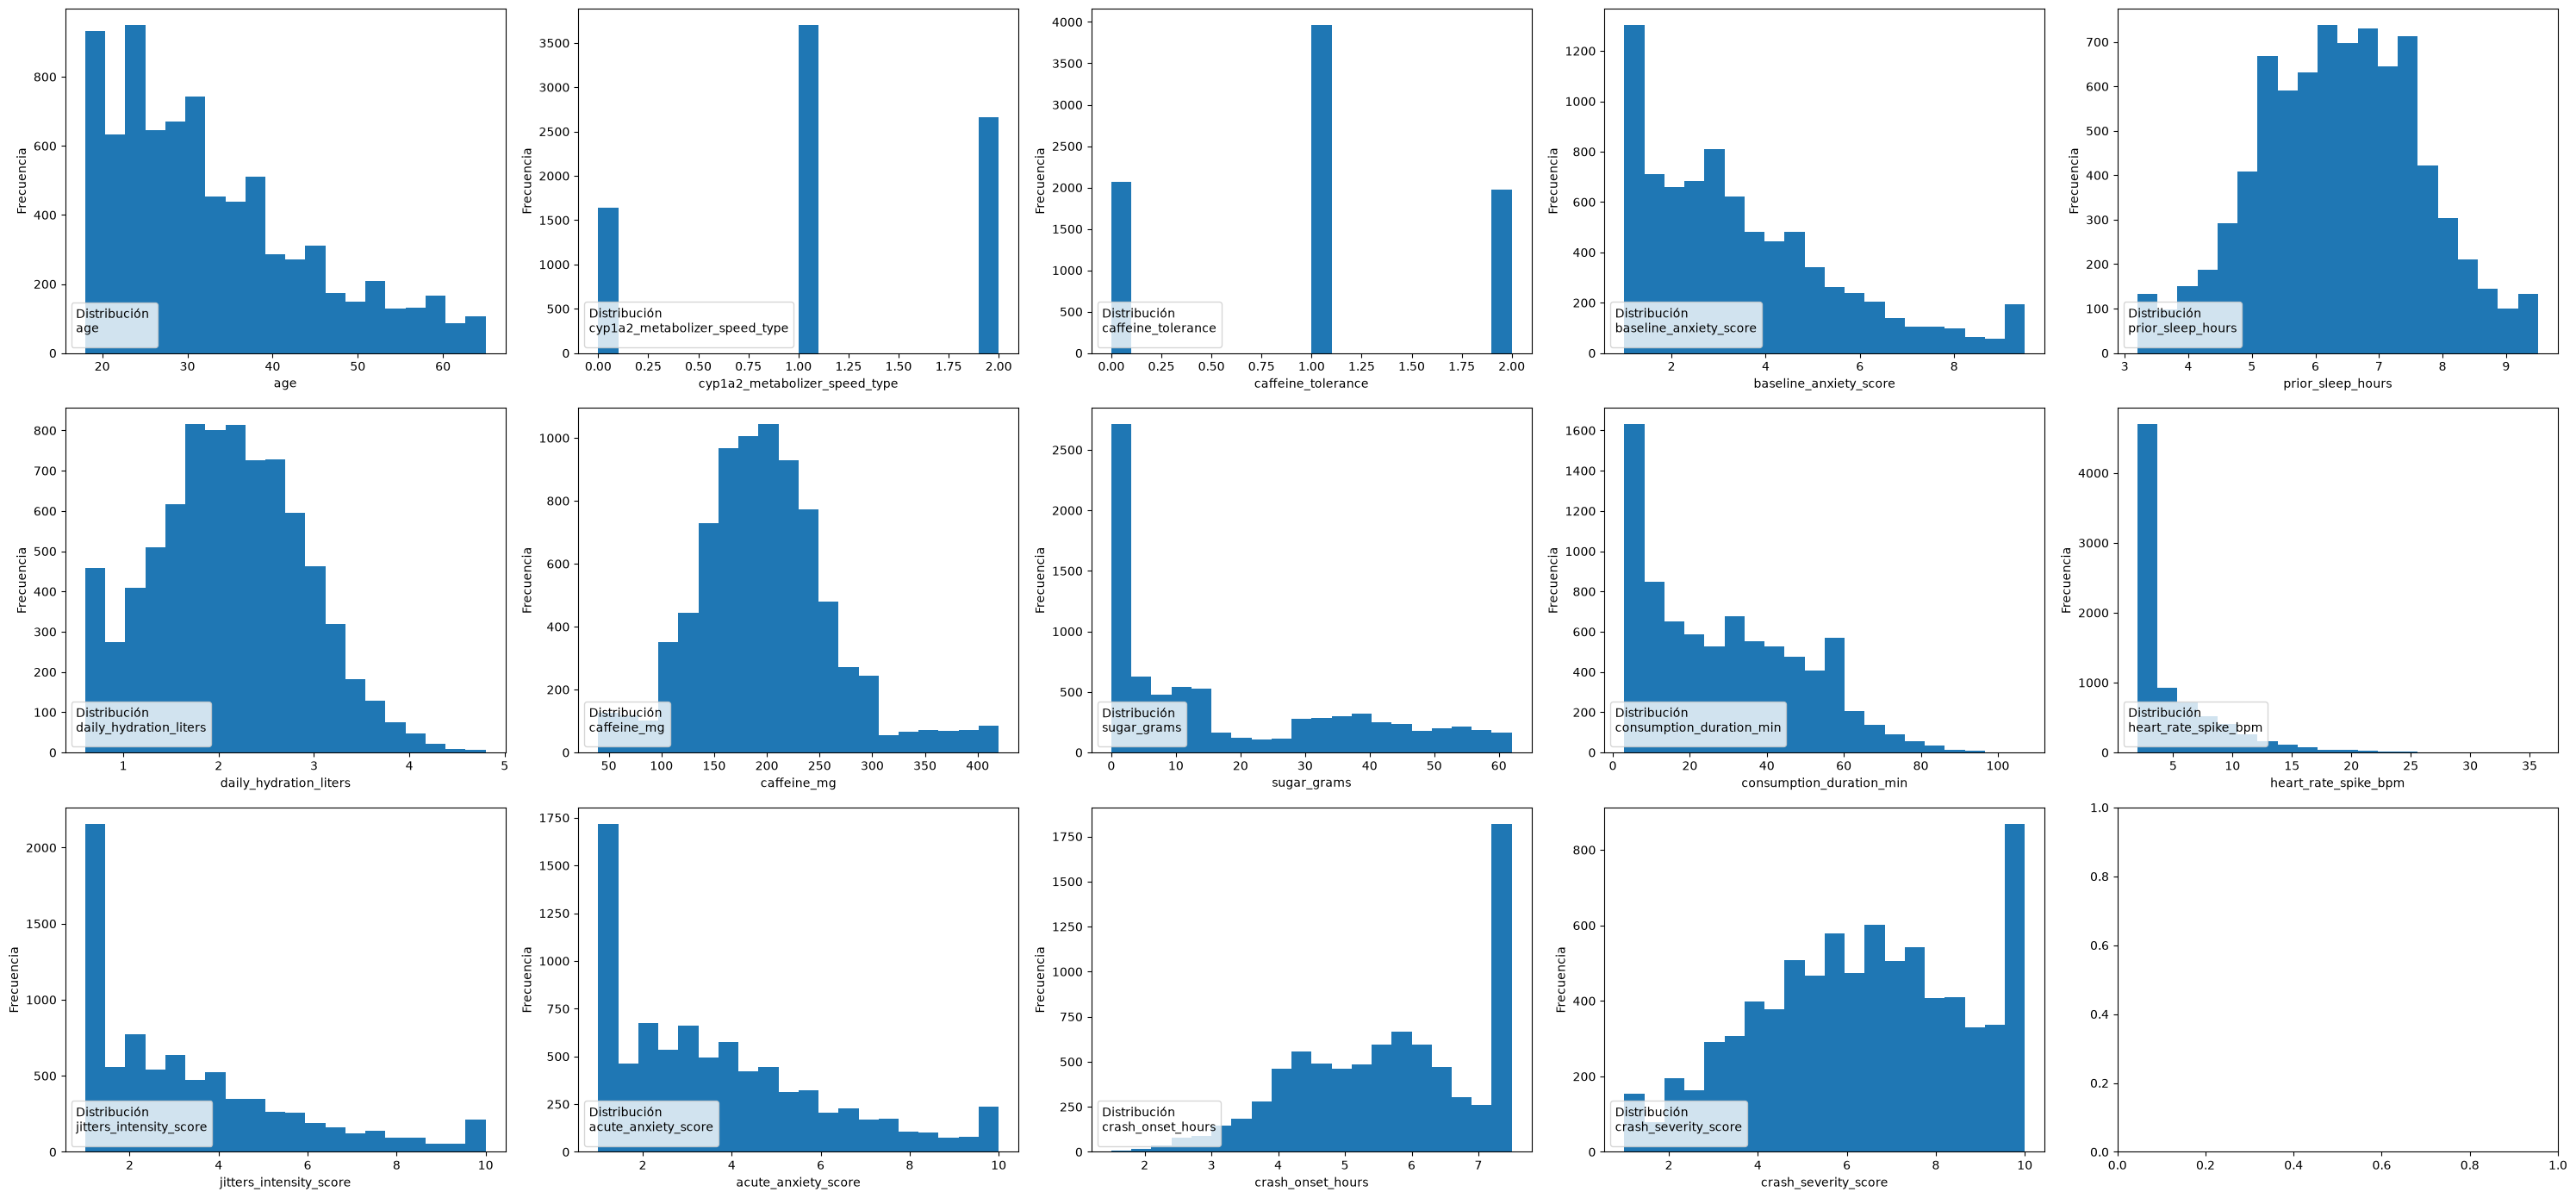

In [8]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
fig, axs = plt.subplots(3,5, figsize=(30, 14))

num_vert = 0; num_hor = 0
for cols in numeric_cols: 
    
    axs[num_vert,num_hor].hist(df[cols], bins=20)
    axs[num_vert,num_hor].legend( title=f'Distribución \n{cols}', loc='lower left')
    axs[num_vert,num_hor].axes.get_xaxis().set_visible(True)
    axs[num_vert,num_hor].axes.get_yaxis().set_visible(True)
    axs[num_vert,num_hor].set_xlabel(f'{cols}')
    axs[num_vert,num_hor].set_ylabel('Frecuencia')
    
    num_hor += 1
    if num_vert == 0 and num_hor == 5:
            num_vert = 1
            num_hor = 0

    elif num_vert == 1 and num_hor == 5:
            num_vert = 2
            num_hor = 0    
        
plt.tight_layout()
fig.show()

Así a vista podemos ver que as nosas variables distribúense en xeral nalgunha clase de distribución exponencial ou gaussiana. Na gran maioría o dato da moda resulta atípico, aínda que realmente podemos pensar que isto é realmente un punto que nos indica que as variables están fortemente ligadas, e.g., que moita xente teña un consumo de azucre próximo a 0 gramos pode xustificar que a maioría dos accidentes ocorran máis de 6 horas despois da inxesta se é que o azucre funciona como un catalizador; ou, máis obvio, que a gran maioría de persoas non se autoperciban síntomas de tremores pode coincidir con non detectar unha $\Delta$ BPM tamén na gran maioría. Nos casos gaussianos atopamos unha distribución interesante sobre hábitos de vida como a cantidade de auga que se bebe como as de horas que durmen. Tamén nos decatamos que a gran maioría de pacentes foron precisamente xente xove (menores de 34 anos) aos que se asocia un maior número de consumo de bebidas enerxéticas fronte a formas tradicionais de consumo de cafeína (café ou té).

In [9]:
# quero dar a moda e media de 3 distrbucións
distrib = ('prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg' ,'crash_onset_hours', 'crash_severity_score')
for cat in distrib:
    print(f'En {cat} a media é {df[cat].mean():.2f} e a moda é {df[cat].mode().tolist()[0]}')

En prior_sleep_hours a media é 6.38 e a moda é 6.7
En daily_hydration_liters a media é 2.11 e a moda é 0.6
En caffeine_mg a media é 198.04 e a moda é 197
En crash_onset_hours a media é 5.65 e a moda é 7.5
En crash_severity_score a media é 6.29 e a moda é 10.0


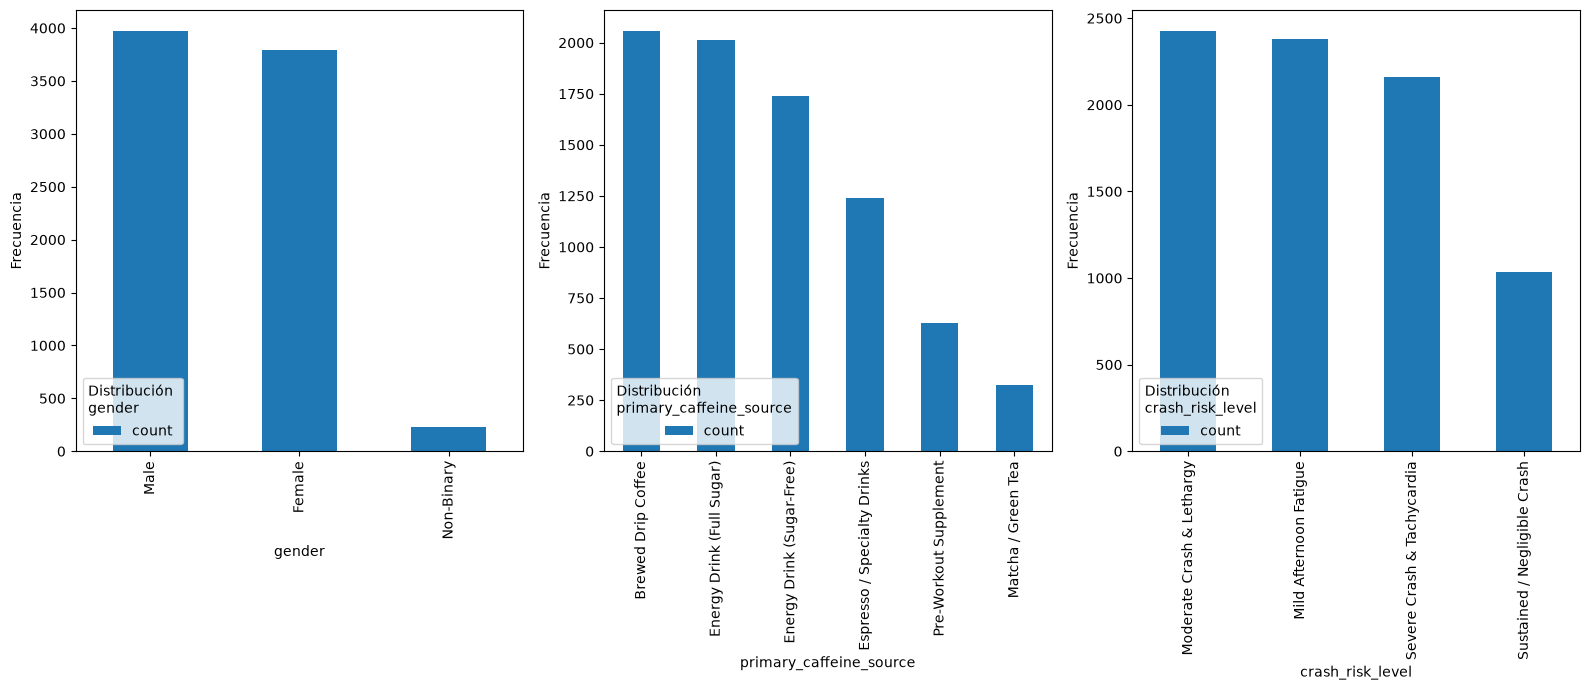

In [10]:
categorical_cols = df.select_dtypes(include=['object']).columns

fig, axs = plt.subplots(1,3, figsize=(16, 7))

num_hor = 0
for col in categorical_cols[1:]:
    df[col].value_counts().plot(kind='bar', ax=axs[num_hor])
    axs[num_hor].legend(title=f'Distribución \n{col}', loc='lower left')
    axs[num_hor].set_xlabel(col)
    axs[num_hor].set_ylabel('Frecuencia')
    num_hor += 1
        
plt.tight_layout()
fig.show()

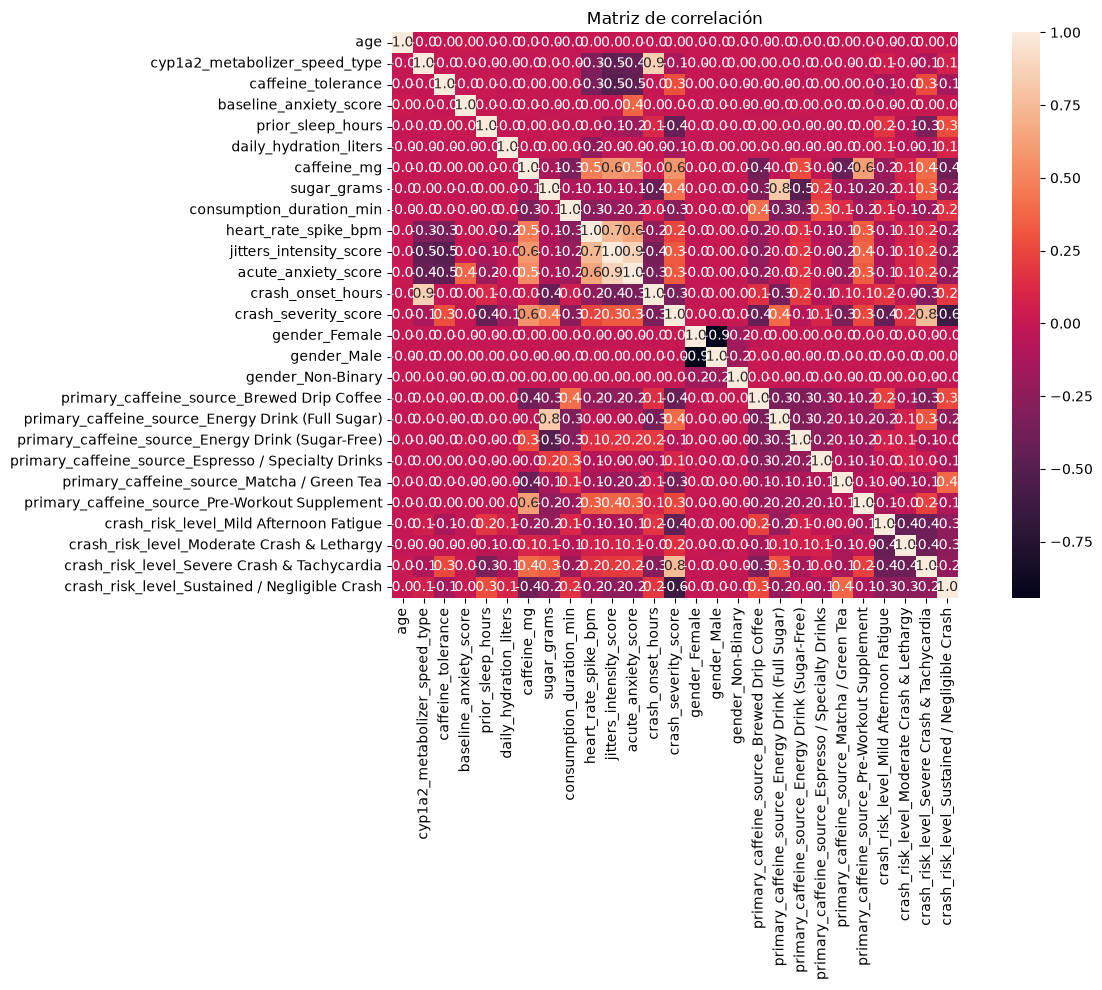

In [11]:
# Aquí empregamos o DataFrame Df, onde eliminamos as columnas categóricas e integramos os dummies correspondentes a cada 
# unha delas; é necesario para facer unha correlación numéricas.

# mapa de calor
plt.figure(figsize=(14, 10))
sns.heatmap(pd.concat([Df.drop(columns=['crash_risk_level']),crash_risk_level_dummies],axis=1).select_dtypes(include='number').corr(), annot=True, fmt='.1f', square=True#, cmap='coolwarm'
            )
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

Vemos que na diagonal aparecen 3 cadradados pequenos de correlación negativa moi significativa, isto derívase de que son as submatrices das variables dummies que son autoexcluíntes. Obviamente non pode haber un suxeito home e muller á vez (obviando identificacións de xénero fluído) ou que alguén teña dúas gravidades distintas no crash. 

Vemos a continuación un pouco máis en detalle algunha variable significativa nas predicións.

In [12]:
# imos facer categorías para caffeine_mg e sugar_grams, comparadas co tipo de accidente e tamén o consumido fronte o accidente. As categorías que collan o 33% dos datos ou o 25, 50, 25 (percentiles)
p25, p75 = df["caffeine_mg"].quantile([0.25, 0.75])
p33, p66 = df["sugar_grams"].quantile([0.3333, 0.6666])

def categorize_caffeine(score): # en cuartiles (aínda que o primer 25 chega aos 157mg que me parece pila)
    if score <= p25: # <25%
        return 'Low'
    elif score <= p75: # 25 - 75%
            return 'Medium'
    else:
        return 'High' # >75%

def categorize_sugar(score): # en terciles 
    if score <= p33: # <33.33%
        return 'Low'
    elif score <= p66:
            return 'Medium' # 33.33-66.66%
    else:
        return 'High' # >66.66%

caffeine_level = df['caffeine_mg'].apply(categorize_caffeine)
sugar_level = df['sugar_grams'].apply(categorize_sugar)

# Poderiamos facelo en realidade para calquera parámetro, escollemos idade e xénero por evidenciar se as mental illness están sesgados por eles 
corr_cafe_sugar_source = pd.concat([caffeine_level, sugar_level, df['primary_caffeine_source'],df['crash_risk_level']], axis=1)
corr_cafe_sugar_source.head()

,caffeine_mg,sugar_grams,primary_caffeine_source,crash_risk_level
0,Low,Medium,Brewed Drip Coffee,Mild Afternoon Fatigue
1,Medium,Low,Energy Drink (Sugar-Free),Sustained / Negligible Crash
2,Medium,High,Energy Drink (Full Sugar),Moderate Crash & Lethargy
3,High,Low,Pre-Workout Supplement,Severe Crash & Tachycardia
4,Medium,High,Energy Drink (Full Sugar),Severe Crash & Tachycardia


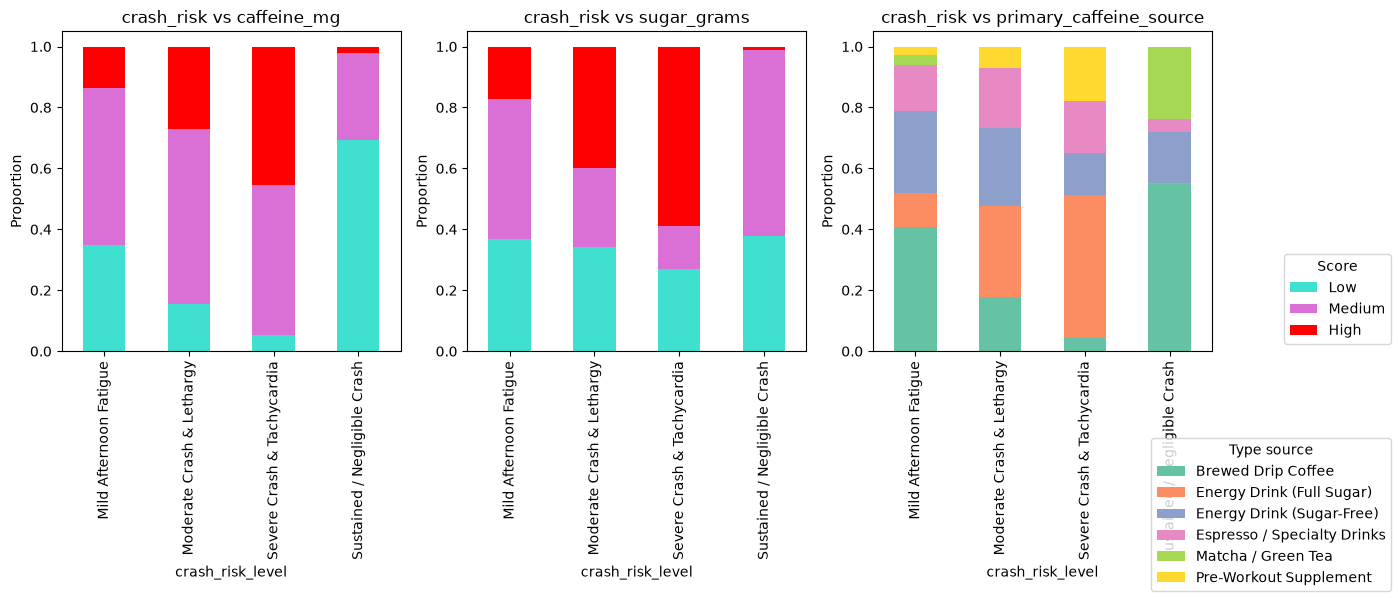

In [13]:
Scores = ('caffeine_mg', 'sugar_grams')
Rangos = ('Low', 'Medium', 'High')
cores = ['turquoise', 'orchid', 'r']

fig, axs = plt.subplots(1, 3, figsize=(14, 6))

for i, score in enumerate(Scores):
    score_distribution = (
        corr_cafe_sugar_source
        .groupby('crash_risk_level')[score]
        .value_counts(normalize=True)
        .unstack()
        .reindex(columns=Rangos, fill_value=0)
        )

    score_distribution.plot(
        kind='bar',
        stacked=True,
        ax=axs[i],
        color=cores,
        legend=False
        )
    
    axs[i].set_title(f'crash_risk vs {score}')
    # axs[i].set_xlabel('Crash risk level') # non creo que falla falta, é bsatante intuitiva a gráfica
    axs[i].set_ylabel('Proportion')

# facemos un plot especial para poder ver stackeadas dúas variables str por proporción
crash_vs_source = pd.crosstab(corr_cafe_sugar_source['crash_risk_level'], corr_cafe_sugar_source['primary_caffeine_source'], normalize='index')
cores = sns.color_palette('Set2', n_colors=crash_vs_source.shape[1])
crash_vs_source.plot(kind='bar', stacked=True, ax=axs[2], color=cores, legend=False)
axs[2].set_title(f'crash_risk vs primary_caffeine_source')
axs[2].set_ylabel('Proportion')

handles, labels = axs[0].get_legend_handles_labels()
handles1, labels1 = axs[2].get_legend_handles_labels()
fig.legend(handles, labels, title='Score', loc='center right')
fig.legend(handles1, labels1, title='Type source', loc='lower right')

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

Agora, previo a proceder ás dúas análises de predicción das variables <<Depression_Score>>, <<Anxiety_Score>> e <<Loneliness_Score>> debemos separar as nosas mostras de datos en datos de entrenamento e de testeo. Será necesario que utilizemos o dataframe onde substituímos as columnas str polos dummies respectivos (Df) e ademais empregamos a división en niveis (Low, Medium, High) que fixemos anteriormente e as transformamos a variables numéricas cun diccionario; así só "predicimos" que alguén sexa pouco, algo ou moi depresivo.

In [14]:
y = Df.crash_risk_level

labels_1 = ['Mild Afternoon Fatigue', # son os elementos de y, será necesario telo definido
    'Moderate Crash & Lethargy',
    'Severe Crash & Tachycardia',
    'Sustained / Negligible Crash'] 

Podemos propoñer dous tipos de análises, un onde descartamos os outros y'es para un y'dado (i.e., descartamos a dependencia de ansiedad, depresión e loneliness) o cal non creo que teña moito sentido porque no DSM-5 sinálase a soidade como factor de risco da depresión e á vez tamén que as sintomatoloxías ansiosas e depresivas están fortemente ligadas acabando por difuminarse. Así que temos que escoller uns datos X para cada Y onde no X só se descarte o propio Y.

In [15]:
x = Df.drop(columns=['crash_risk_level','crash_severity_score'])

In [16]:
split = round(x.shape[0]*0.80) # todas as X son do mesmo tamaño, non distinguimos, 80% de entreno e 20% de testeo
X1_train, X1_test = x[:split], x[split:] # creo que isto podo facelo logo para a rede e con sklearn uso algo interno
y1_train, y1_test = y[:split], y[split:]

# En principio fago a partición con sklearn

## 3. Análise con sklearn (regresión loxística)

Non sei moi ben que teño que facer aquí

In [17]:
# from sklearn.preprocessing import MinMaxScaler
# X_scaler = MinMaxScaler()
# y_scaler = MinMaxScaler()
# x1 = X_scaler.fit_transform(X_anx)
# x2 = X_scaler.fit_transform(X_dep)
# x3 = X_scaler.fit_transform(X_lon)
# y1 = y_scaler.fit_transform(y_anx)
# y2 = y_scaler.fit_transform(y_dep)
# y3 = y_scaler.fit_transform(y_lon)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x1_train_scaled = scaler.fit_transform(X1_train)
x1_test_scaled = scaler.transform(X1_test)

In [18]:
# from sklearn.model_selection import train_test_split
# x1_train, x1_test, y1_train, y1_test = train_test_split(x1, y1, test_size=0.15, random_state=100)
# x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y2, test_size=0.20, random_state=100)
# x3_train, x3_test, y3_train, y3_test = train_test_split(x3, y3, test_size=0.20, random_state=100)

# from sklearn.svm import SVR
# svr_rbf = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=.1)
# svr_lin = SVR(kernel='linear', C=100, gamma='scale')
# svr_poly = SVR(kernel='poly', C=100, gamma='auto', degree=3, epsilon=.1, coef0=1)

In [19]:
from sklearn import linear_model
from sklearn.model_selection import cross_val_score

# y1_train_class = np.rint(y1_train.ravel() * 2).astype(int) # non me debería facer falta porque xa non renormalizo as y's

alpha = np.arange(1e-15, 0.000001, 0.00000005)
val_scores = np.zeros(len(alpha))

for i, a in enumerate(alpha):
    model_cross = linear_model.SGDClassifier(
            loss='hinge', penalty='l2', alpha=a, random_state=100
        )
    score = cross_val_score(model_cross, x1_train_scaled, y1_train, cv=5)
    val_scores[i] = score.mean()

ind = np.argmax(val_scores)
# alpha[ind] = 0.005
print('O mellor valor de alpha é', alpha[ind])


O mellor valor de alpha é 7.50000001e-07


In [20]:
model_star = linear_model.SGDClassifier(loss='hinge', penalty='l2', alpha=alpha[ind])
model_trained = model_star.fit(x1_train_scaled, y1_train)

y_hat_train_1 = model_trained.predict(x1_train_scaled)
y_hat_test_1 = model_trained.predict(x1_test_scaled)

print('La exactitud del entrenamiento es', model_trained.score(x1_train_scaled, y1_train))

La exactitud del entrenamiento es 0.57453125


In [21]:
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print("Entrenamiento:", accuracy_score(y1_train, y_hat_train_1))
print("Prueba:", accuracy_score(y1_test, y_hat_test_1))

print(
    classification_report(
        y1_test,
        y_hat_test_1,
        target_names=labels_1
    )
)

Entrenamiento: 0.57453125
Prueba: 0.590625
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.47      0.53      0.50       443
   Moderate Crash & Lethargy       0.46      0.42      0.44       509
  Severe Crash & Tachycardia       0.77      0.86      0.81       435
Sustained / Negligible Crash       0.80      0.59      0.68       213

                    accuracy                           0.59      1600
                   macro avg       0.63      0.60      0.61      1600
                weighted avg       0.59      0.59      0.59      1600



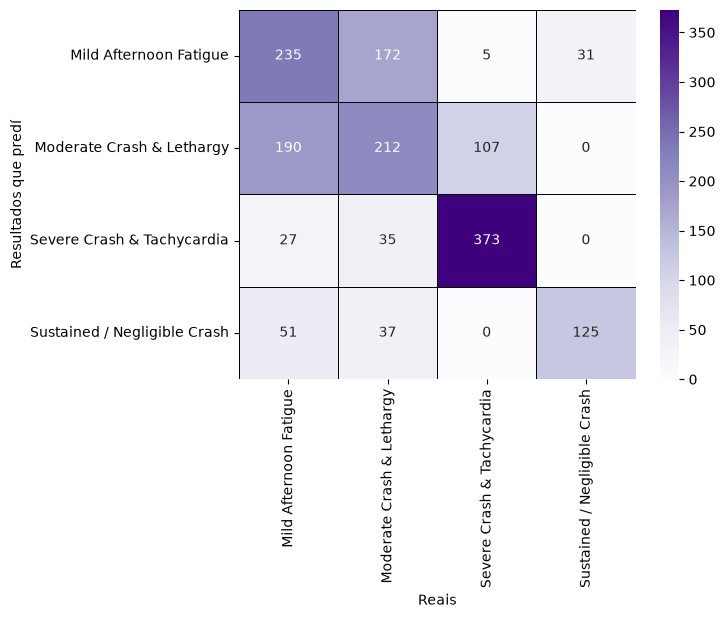

In [22]:
from sklearn.metrics import confusion_matrix

cm_1 = confusion_matrix(y1_test, y_hat_test_1, labels=labels_1)

sns.heatmap(cm_1, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Resultados que predí') #Ponemos título al eje y
plt.xlabel('Reais') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor

In [23]:
from sklearn.svm import SVC

model = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

model_trained2 = model.fit(x1_train_scaled, y1_train)

y_hat_train_2 = model_trained2.predict(x1_train_scaled)
y_hat_test_2 = model_trained2.predict(x1_test_scaled)

print('La exactitud del entrenamiento es', model_trained2.score(x1_train_scaled, y1_train))

La exactitud del entrenamiento es 0.84015625


In [24]:
print("Entrenamiento:", accuracy_score(y1_train, y_hat_train_2))
print("Prueba:", accuracy_score(y1_test, y_hat_test_2))

print(
    classification_report(
        y1_test,
        y_hat_test_2,
        target_names=labels_1
    )
)

Entrenamiento: 0.84015625
Prueba: 0.775
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.72      0.77      0.74       443
   Moderate Crash & Lethargy       0.72      0.77      0.75       509
  Severe Crash & Tachycardia       0.89      0.82      0.85       435
Sustained / Negligible Crash       0.84      0.70      0.77       213

                    accuracy                           0.78      1600
                   macro avg       0.79      0.77      0.78      1600
                weighted avg       0.78      0.78      0.78      1600



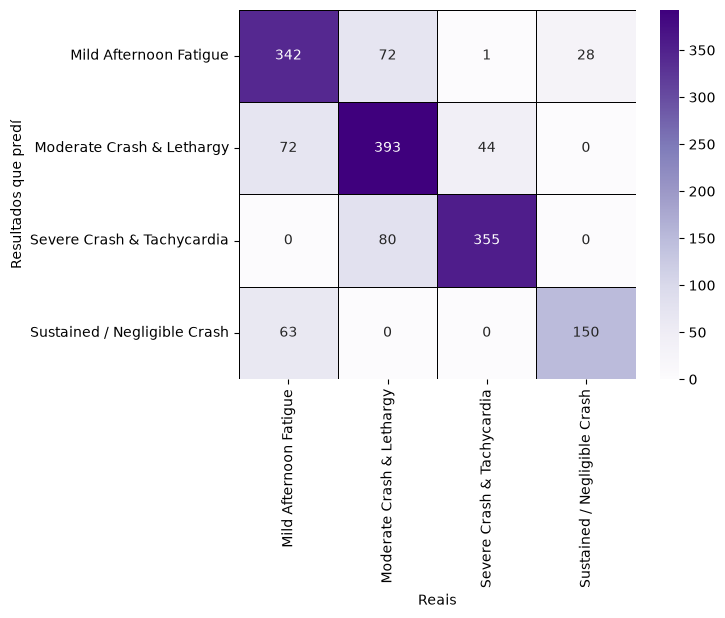

In [25]:
cm_2 = confusion_matrix(y1_test, y_hat_test_2, labels=labels_1)

sns.heatmap(cm_2, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Resultados que predí') #Ponemos título al eje y
plt.xlabel('Reais') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor

## 3.1 facemos outro drop

x = Df.drop(columns=['crash_risk_level','crash_severity_score'])

# 4. Análise con tensorflow (rede neuronal)

In [26]:
import tensorflow as tf

from keras import layers
from keras.models import Sequential

model = tf.keras.Sequential([
    layers.Input(shape=(116,)),
    layers.Dense(30, activation='relu'),
    layers.Dense(30, activation='relu'),
    layers.Dense(30, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

teño que usar os y'es con só 3 valores, empregaría Low, Meddium, High --> 0,1,2

La exactitud del entrenamiento es 1.0


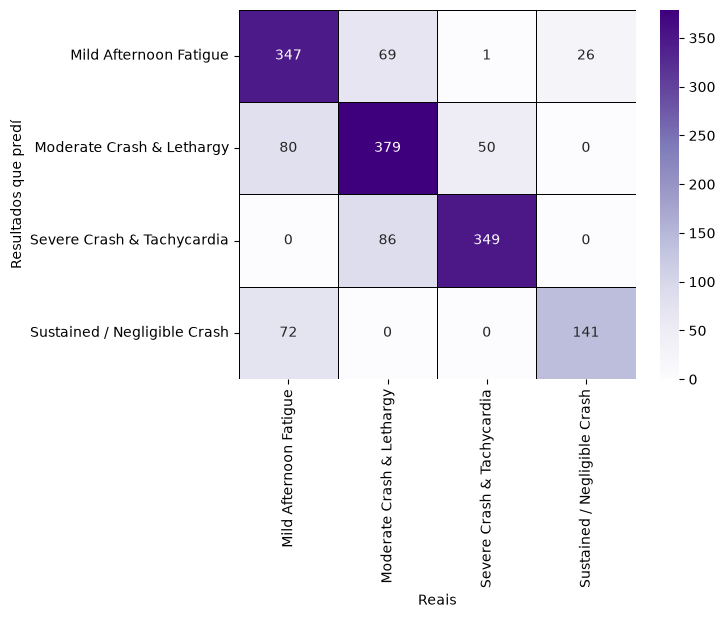

Entrenamiento: 1.0
Prueba: 0.76
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.70      0.78      0.74       443
   Moderate Crash & Lethargy       0.71      0.74      0.73       509
  Severe Crash & Tachycardia       0.87      0.80      0.84       435
Sustained / Negligible Crash       0.84      0.66      0.74       213

                    accuracy                           0.76      1600
                   macro avg       0.78      0.75      0.76      1600
                weighted avg       0.77      0.76      0.76      1600



In [27]:
from sklearn.ensemble import RandomForestClassifier

modelF = RandomForestClassifier(
    n_estimators=200,
    random_state=100
)

model_trained3 = modelF.fit(x1_train_scaled, y1_train)

y_hat_train_3 = model_trained3.predict(x1_train_scaled)
y_hat_test_3 = model_trained3.predict(x1_test_scaled)

print('La exactitud del entrenamiento es', model_trained3.score(x1_train_scaled, y1_train))




cm_3 = confusion_matrix(y1_test, y_hat_test_3, labels=labels_1)

sns.heatmap(cm_3, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Resultados que predí') #Ponemos título al eje y
plt.xlabel('Reais') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor


print("Entrenamiento:", accuracy_score(y1_train, y_hat_train_3))
print("Prueba:", accuracy_score(y1_test, y_hat_test_3))

print(
    classification_report(
        y1_test,
        y_hat_test_3,
        target_names=labels_1
    )
)

La exactitud del entrenamiento es 0.99671875


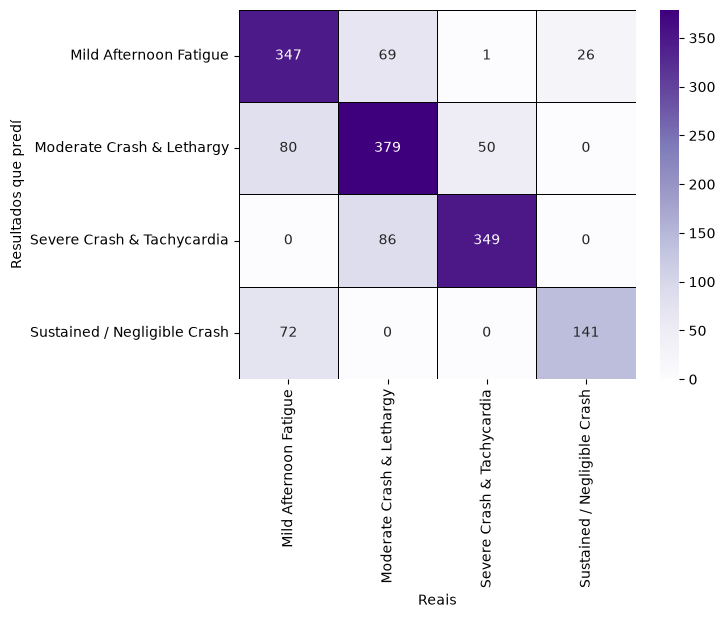

Entrenamiento: 0.99671875
Prueba: 0.7675
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.70      0.75      0.73       443
   Moderate Crash & Lethargy       0.73      0.75      0.74       509
  Severe Crash & Tachycardia       0.88      0.83      0.86       435
Sustained / Negligible Crash       0.79      0.70      0.74       213

                    accuracy                           0.77      1600
                   macro avg       0.77      0.76      0.77      1600
                weighted avg       0.77      0.77      0.77      1600



In [28]:
from sklearn.ensemble import HistGradientBoostingClassifier

modelHF = HistGradientBoostingClassifier(
    random_state=100
)

model_trained4 = modelHF.fit(x1_train_scaled, y1_train)

y_hat_train_4 = model_trained4.predict(x1_train_scaled)
y_hat_test_4 = model_trained4.predict(x1_test_scaled)

print('La exactitud del entrenamiento es', model_trained4.score(x1_train_scaled, y1_train))



cm_4 = confusion_matrix(y1_test, y_hat_test_4, labels=labels_1)

sns.heatmap(cm_3, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Resultados que predí') #Ponemos título al eje y
plt.xlabel('Reais') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor


print("Entrenamiento:", accuracy_score(y1_train, y_hat_train_4))
print("Prueba:", accuracy_score(y1_test, y_hat_test_4))

print(
    classification_report(
        y1_test,
        y_hat_test_4,
        target_names=labels_1
    )
)

In [29]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    X1_train,
    y1_train,
    random_state=100
)

for col, val in sorted(zip(x.columns, mi),
                       key=lambda x: x[1],
                       reverse=True):
    print(col, round(val,4))

# aquí vemos que a columna <<crash_severity_score>> ten un 1.34 de correlación o que quere dicir que lle está "chivando" moita
# información ao modelo, o seu sería ver como se comporta sen empregar esta columna, logo, repetindo considerando ese caso 

caffeine_mg 0.2007
sugar_grams 0.1776
prior_sleep_hours 0.1007
primary_caffeine_source_Brewed Drip Coffee 0.0934
primary_caffeine_source_Energy Drink (Full Sugar) 0.0786
crash_onset_hours 0.07
jitters_intensity_score 0.0676
primary_caffeine_source_Matcha / Green Tea 0.0589
acute_anxiety_score 0.051
caffeine_tolerance 0.0459
heart_rate_spike_bpm 0.0429
primary_caffeine_source_Pre-Workout Supplement 0.0376
consumption_duration_min 0.0246
baseline_anxiety_score 0.0205
gender_Female 0.0184
primary_caffeine_source_Energy Drink (Sugar-Free) 0.0084
primary_caffeine_source_Espresso / Specialty Drinks 0.0054
daily_hydration_liters 0.0054
age 0.0042
cyp1a2_metabolizer_speed_type 0.0
gender_Male 0.0
gender_Non-Binary 0.0
